# Bioprocess yield: red pigment from a published fermentation design

How do initial pH, temperature, agitation, and fermentation time relate to red pigment yield of *Talaromyces albobiverticillius* 30548, and does a simple model predict a held-out run better than the training mean?

The measurements are Table 2 of Venkatachalam et al., *Microorganisms* 2020, 8, 711 (CC BY 4.0). This notebook calls the same functions as `src/yield_analysis.py`, `src/model_training.py`, and `src/visualization.py`. Run it from the repository root.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from bioprocess.analysis import best_process_conditions, summarize_dataset
from bioprocess.data import DATASET_CITATION, TARGET_COLUMN, load_dataset
from bioprocess.modeling import evaluate_models, quadratic_insample_check
from bioprocess.plots import save_factor_figures, save_prediction_figure

dataset = load_dataset(ROOT / "data" / "venkatachalam_2020_table2.csv")
print(DATASET_CITATION)
print(f"{len(dataset)} runs, target {TARGET_COLUMN}")
dataset.head(3)


Venkatachalam M, Shum-Chéong-Sing A, Dufossé L, Fouillaud M. Microorganisms. 2020;8(5):711. https://doi.org/10.3390/microorganisms8050711
29 runs, target red_pigment_yield_g_l


,run_id,ph_coded,temperature_coded,agitation_coded,time_coded,ph,temperature_c,agitation_rpm,fermentation_time_h,orange_pigment_yield_g_l,red_pigment_yield_g_l,biomass_g_l
0,1,0,0,0,0,6.5,24,150,168,0.30,0.83,3.35
1,2,0,0,1,-1,6.5,24,200,24,1.15,1.44,5.38
2,3,0,1,0,1,6.5,27,150,336,0.30,0.82,1.97


## Yield summary

Orange pigment and dry biomass are co-measured outcomes. They are summarised with the best runs and are not used as predictors.


In [2]:
summary = summarize_dataset(dataset)
for key, value in summary.items():
    print(f"{key}: {value:.3f}" if isinstance(value, float) else f"{key}: {value}")
print()
best_process_conditions(dataset)


total_runs: 29
n_process_factors: 4
n_center_points: 5
average_yield_g_l: 1.300
yield_std_g_l: 0.418
highest_yield_g_l: 1.930
lowest_yield_g_l: 0.430
center_yield_mean_g_l: 1.248
center_yield_std_g_l: 0.355



,run_id,ph,temperature_c,agitation_rpm,fermentation_time_h,red_pigment_yield_g_l,orange_pigment_yield_g_l,biomass_g_l
0,27,4.0,24,100,168,1.93,1.76,6.79
1,28,6.5,24,200,336,1.93,1.77,7.17
2,29,6.5,24,100,336,1.93,1.75,6.65


## Factor plots

Each point is one design run. The horizontal line inside a box is the median.


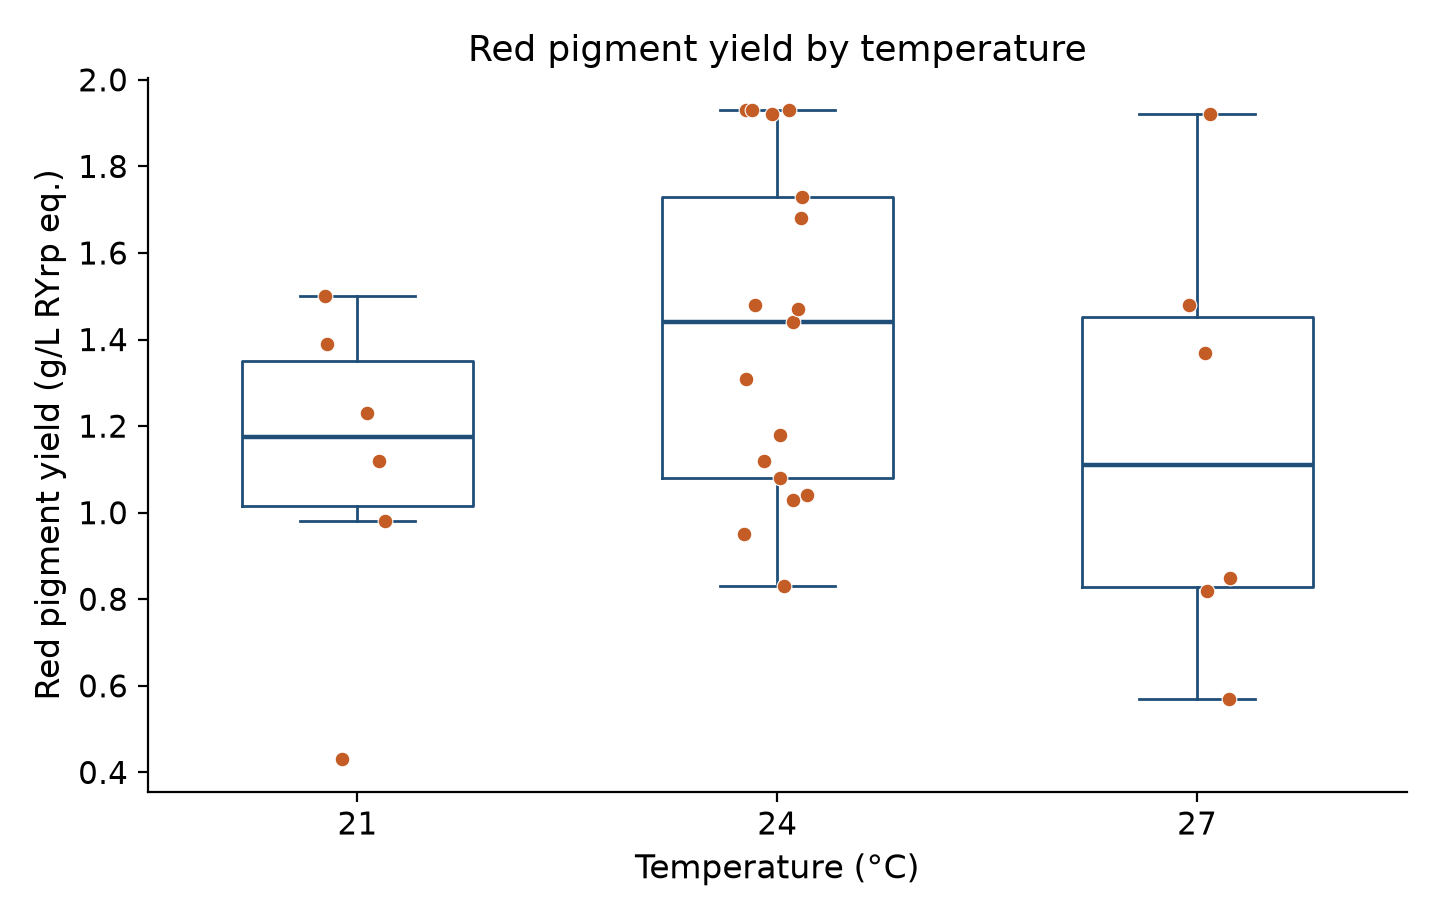

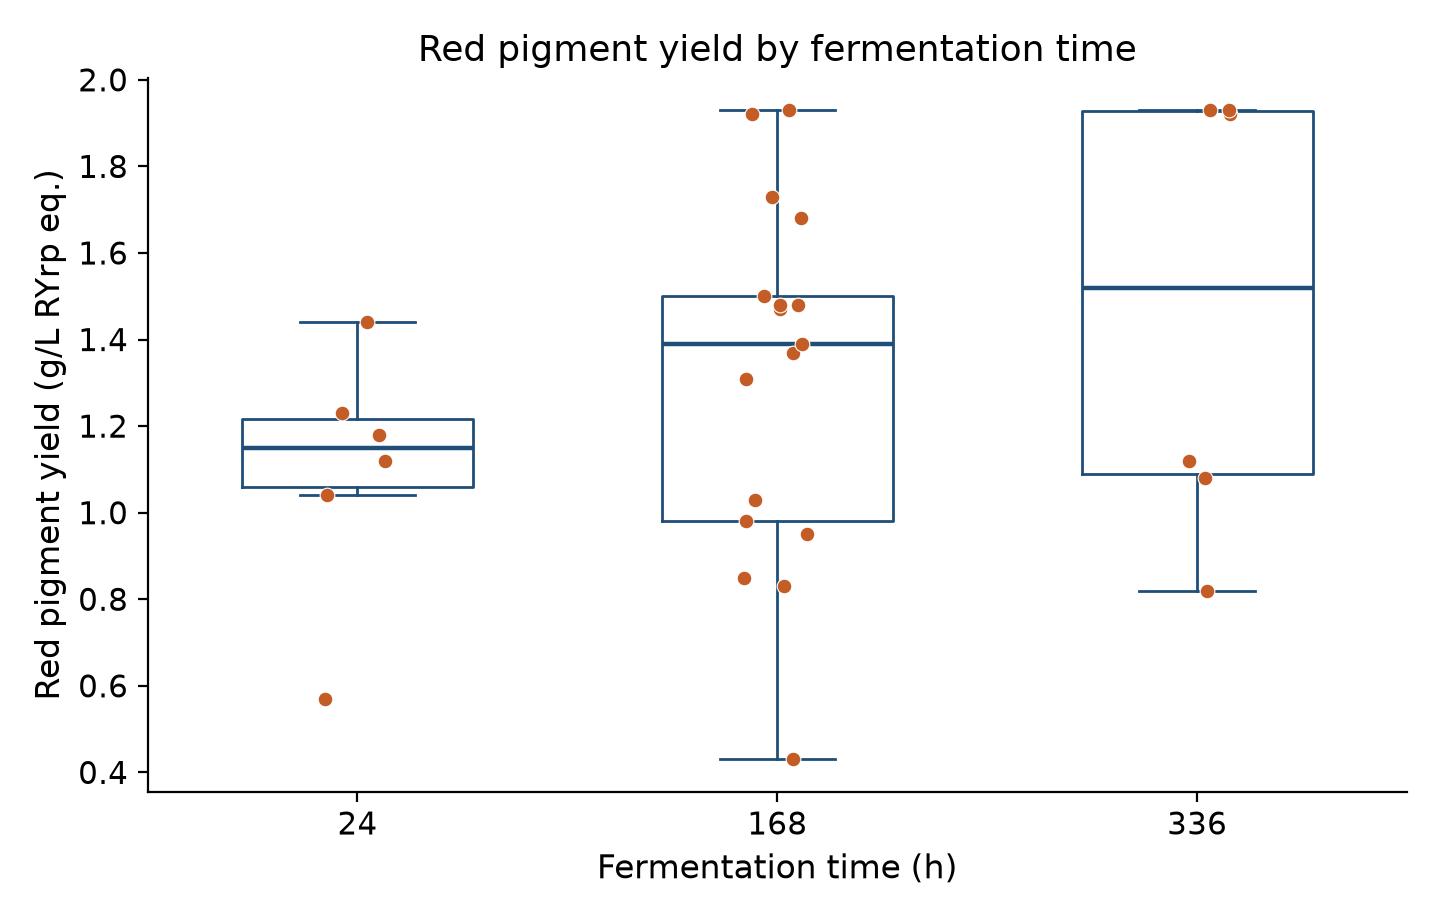

In [3]:
figures = ROOT / "figures"
save_factor_figures(dataset, figures)
for name in ("temperature_vs_yield.png", "fermentation_time_vs_yield.png"):
    display(Image(filename=str(figures / name)))


## Cross-validation

Leave-one-out holds out one run at a time. Repeated cross-validation is 5-fold, repeated 10 times (`random_state=42`). The mean baseline predicts the training-fold mean. The random forest uses 200 trees and `min_samples_leaf=2`, fixed in advance.


In [4]:
summary_table, predictions, _repeats = evaluate_models(dataset)
show = summary_table[
    [
        "label",
        "loo_mae",
        "loo_rmse",
        "loo_r2",
        "loo_abs_error_std",
        "loo_abs_error_min",
        "loo_abs_error_max",
        "repeated_cv_mae_mean",
        "repeated_cv_mae_std",
        "repeated_cv_r2_mean",
        "repeated_cv_r2_std",
    ]
].copy()
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print(show.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


                     label  loo_mae  loo_rmse  loo_r2  loo_abs_error_std  loo_abs_error_min  loo_abs_error_max  repeated_cv_mae_mean  repeated_cv_mae_std  repeated_cv_r2_mean  repeated_cv_r2_std
             Mean baseline    0.355     0.426  -0.073              0.238              0.010              0.901                 0.354                0.005               -0.076               0.035
         Linear regression    0.406     0.481  -0.368              0.262              0.010              0.986                 0.407                0.026               -0.389               0.176
Quadratic response surface    0.550     0.649  -1.492              0.350              0.051              1.327                 0.660                0.116               -2.675               1.125
             Random forest    0.400     0.469  -0.304              0.249              0.028              1.055                 0.387                0.026               -0.271               0.132


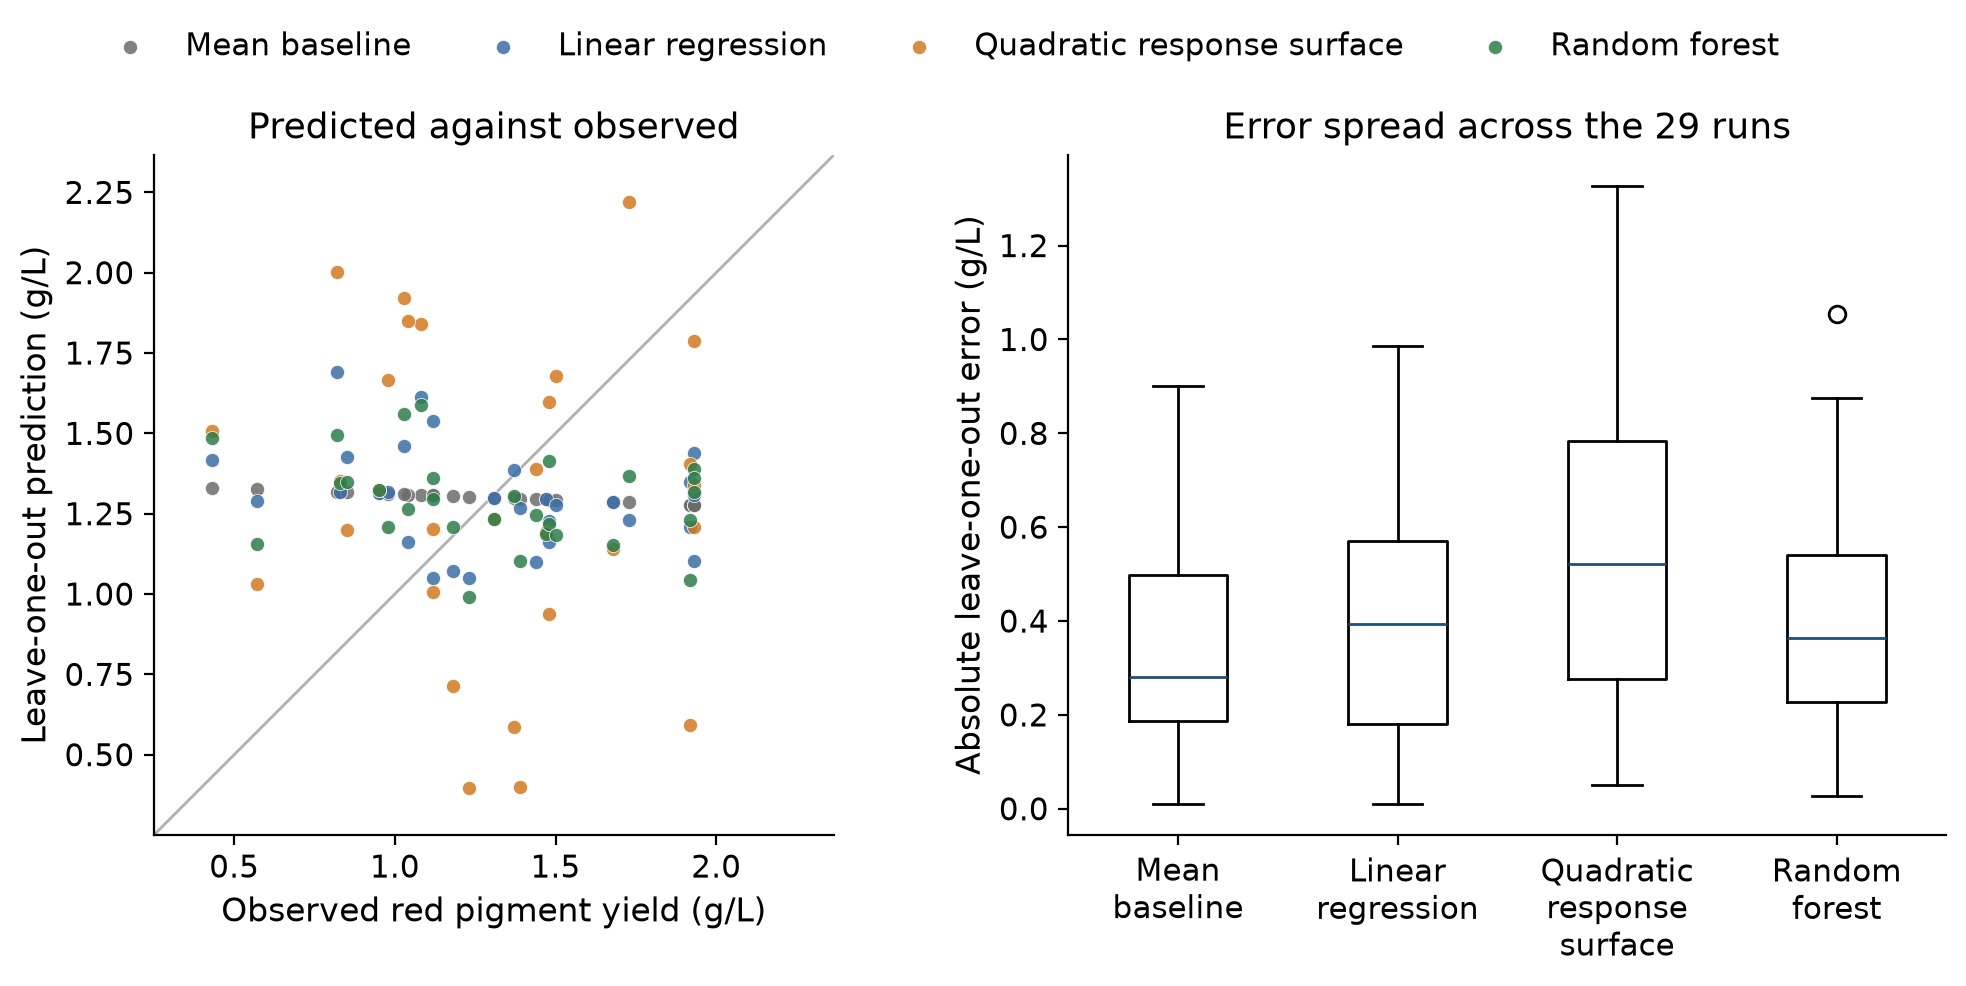

In [5]:
save_prediction_figure(predictions, figures)
display(Image(filename=str(figures / "loo_predicted_vs_observed.png")))


## What the scores say

R² below zero means the predictions are worse than always using the grand mean of all 29 yields. Compare models by MAE. On this table the mean baseline has the lowest leave-one-out MAE and the lowest repeated-cross-validation MAE.

The quadratic surface fits the same runs it is scored on much more closely than it predicts a held-out run. The check below is that in-sample fit. It is not a test score. Equation (9) in the article reports a different intercept and a much higher in-sample R²; those article figures are not recovered from the printed table.


In [6]:
check = quadratic_insample_check(dataset)
for key, value in check.items():
    print(f"{key}: {value:.4f}")


insample_r2: 0.4925
insample_mae: 0.2528
predicted_center_g_l: 1.2480
center_observation_mean_g_l: 1.2480
center_observation_std_g_l: 0.3547
paper_equation_9_intercept_g_l: 1.9200
paper_reported_insample_r2: 0.9734
